<div class=“alert alert-primary” role=“alert”>

<h1 align=“center”>Sixth Practice: Interactive Equilateral Triangle Drawing with History Management</h1>

<h3>1. Coordinate Mathematics & Mouse Interaction</h3>

<p>Implement a mouse callback function that tracks click and drag events. Use geometric formulas (involving <code>math.sqrt(3)</code>) to calculate the third vertex, ensuring the triangle remains perfectly equilateral regardless of mouse movement.</p>

<h3>2. Dynamic Preview & Persistent Drawing</h3>

<p>Utilize <code>img.copy()</code> during the <code>cv.EVENT_MOUSEMOVE</code> phase to show a real-time preview. Once the mouse button is released, the final coordinates are committed to the main canvas using <code>cv.polylines</code>.</p>

<h3>3. Implementation of Undo and Redo Logic</h3>

<p>Manage drawing history by maintaining two stacks: <code>points</code> and <code>redo_points</code>. The ‘z’ key removes the last shape, while the ‘y’ key restores it. A parallel <code>colors</code> list ensures that each shape retains its original color during reconstruction.</p>

<h3>4. Real-time Keyboard Color Selection</h3>

<p>Enable dynamic color switching via keyboard interrupts. Standard colors are assigned to single keys (e.g., ‘r’, ‘g’, ‘b’), and advanced key combinations (like <code>Ctrl+b</code> for black) are handled to provide a professional drawing tool experience.</p>

<hr>

<p><b>Note:</b> Accurate <code>pop()</code> and <code>append()</code> operations between stacks are crucial to keeping the <code>points</code> and <code>colors</code> lists synchronized during Undo and Redo cycles.</p>

</div>

<div class="alert alert-warning" role="alert" align="center">
    <h4>Marzieh Naseri</h4>
</div>

In [9]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import math
import keyboard

In [2]:
event=[i for i in dir(cv2) if "EVENT" in i ]
event

['EVENT_FLAG_ALTKEY',
 'EVENT_FLAG_CTRLKEY',
 'EVENT_FLAG_LBUTTON',
 'EVENT_FLAG_MBUTTON',
 'EVENT_FLAG_RBUTTON',
 'EVENT_FLAG_SHIFTKEY',
 'EVENT_LBUTTONDBLCLK',
 'EVENT_LBUTTONDOWN',
 'EVENT_LBUTTONUP',
 'EVENT_MBUTTONDBLCLK',
 'EVENT_MBUTTONDOWN',
 'EVENT_MBUTTONUP',
 'EVENT_MOUSEHWHEEL',
 'EVENT_MOUSEMOVE',
 'EVENT_MOUSEWHEEL',
 'EVENT_RBUTTONDBLCLK',
 'EVENT_RBUTTONDOWN',
 'EVENT_RBUTTONUP']

In [5]:
cv2.polylines??

Docstring:
polylines(img, pts, isClosed, color[, thickness[, lineType[, shift]]]) -> img
.   @brief Draws several polygonal curves.
.   
.   @param img Image.
.   @param pts Array of polygonal curves.
.   @param isClosed Flag indicating whether the drawn polylines are closed or not. If they are closed,
.   the function draws a line from the last vertex of each curve to its first vertex.
.   @param color Polyline color.
.   @param thickness Thickness of the polyline edges.
.   @param lineType Type of the line segments. See #LineTypes
.   @param shift Number of fractional bits in the vertex coordinates.
.   
.   The function cv::polylines draws one or more polygonal curves.
Type:      builtin_function_or_method

[array([[237, 110],
       [234, 350],
       [443, 233]], dtype=int32), array([[276, 176],
       [153, 362],
       [376, 376]], dtype=int32), array([[241, 225],
       [132, 429],
       [363, 421]], dtype=int32), array([[311, 218],
       [139, 481],
       [453, 498]], dtype=int32), array([[242, 168],
       [125, 413],
       [396, 392]], dtype=int32), array([[130, 154],
       [ 92, 341],
       [273, 280]], dtype=int32), array([[156,  83],
       [114, 308],
       [330, 232]], dtype=int32), array([[103,  88],
       [ 25, 330],
       [274, 277]], dtype=int32)]


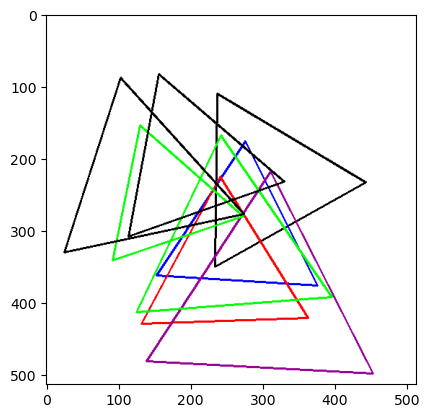

In [10]:
start_point=(0,0)
points=[]
drawing=False
color=(0,0,0)
colors=[]
redo_points=[]
redo_colors=[]

def make_equilateral_triangle(start, current):
    ax, ay = start
    bx, by = current
    dx = bx - ax
    dy = by - ay
    
#third one
    cx = (ax + bx) / 2 + (math.sqrt(3) / 2) * dy
    cy = (ay + by) / 2 - (math.sqrt(3) / 2) * dx
    
    return np.array([start, current, (round(cx), round(cy))], dtype=np.int32)


    
def draw_triangle(event,x,y,flags,param):
    global start_point,points,drawing,color,img
    if event == cv2.EVENT_LBUTTONDOWN:
        start_point=(x,y)
        drawing=True

    elif event==cv2.EVENT_MOUSEMOVE:
        if drawing:
            temp = img.copy()
            triangle = make_equilateral_triangle(start_point, (x, y))
            polygon = triangle.reshape(-1, 1, 2)
            
            # cv2.fillConvexPoly(temp, polygon, color)
            cv2.polylines(temp, [polygon], True, color, 2)
            cv2.imshow("image", temp)
    elif event==cv2.EVENT_LBUTTONUP:
        triangle = make_equilateral_triangle(start_point, (x, y))
        points.append(triangle.copy())
        polygon = triangle.reshape(-1, 1, 2)
        # cv2.fillConvexPoly(img, polygon, color)
        cv2.polylines(img, [polygon], True, color, 2)
        colors.append(color)
        cv2.imshow("image", img)
        drawing=False           

    
#load the image ,clone it.and set up the mouse call back function
img = np.ones((513,513,3),np.uint8)*255
clone =img.copy()
cv2.namedWindow("image")
cv2.setMouseCallback("image",draw_triangle)
        
while True:
    if drawing == False:
        cv2.imshow("image",img)
    key=cv2.waitKey(5) & 0xFF
    if key==ord("c"):
        img=clone.copy()
        points = []
        colors = []
    elif key == ord("z") and points: # with ctrl+z functionality
        img = clone.copy()
        redo_points.append(points.pop())
        redo_colors.append(colors.pop())
        for i in range(len(points)):
            polygon = points[i].reshape(-1, 1, 2)
            # cv2.fillConvexPoly(img, polygon, color)
            cv2.polylines(img, [polygon], True,colors[i], 2)
            cv2.imshow("image", img)
    #redo 
    elif key == ord("y"): # with ctrl+z functionality
        if redo_points:
            img = clone.copy()
            for i in range(len(points)):
                polygon = points[i].reshape(-1, 1, 2)
                # cv2.fillConvexPoly(img, polygon, color)
                cv2.polylines(img, [polygon], True,colors[i], 2)
                cv2.imshow("image", img)
            p=redo_points.pop()
            c=redo_colors.pop()
            points.append(p)
            colors.append(c)
            polygon = p.reshape(-1, 1, 2)
            # cv2.fillConvexPoly(img, polygon, color)
            cv2.polylines(img, [polygon], True,c, 2)
            cv2.imshow("image", img)
            
    # colors
    elif key==ord("r"):
        color=(0,0,255)
    elif key==ord("b"):
        color=(255,0,0)
    elif key==ord("g"):
        color=(0,255,0)
    elif key==ord("p"):
        color=(150,0,150)
    elif keyboard.is_pressed("ctrl") and keyboard.is_pressed("b"):
        color=(0,0,0)
        
    elif key == 27:
        break




# close all open windows
cv2.destroyAllWindows() 

plt.imshow(img[...,::-1])
print(points)